# 1. Análisis Exploratorio de Datos (EDA)
Se realiza sobre los datos crudos **ya divididos**: `data/raw/train/raw_train.csv` y `data/raw/test/raw_test.csv`, generados por `src/pipeline.py`. Esos archivos ya pasaron por: descarte de los nulos de texto, deduplicación agrupada por `track_id` (popularidad máxima entre copias y lista de géneros consolidada), multi-hot de géneros (`MultiLabelBinarizer`) y split agrupado por `song_key` (artista + título, `random_state=42`).

Aquí se aplican las transformaciones (`log1p` en las variables asimétricas y definición del target `hit`) y el análisis se hace con **train**. Test se usa solo para verificar que las transformaciones se apliquen sin fuga y para medir el peso del género fuera de muestra.

> El umbral P80 se calcula **solo con train** y se aplica a test (ver `src/pipeline.py`).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# Los .py y data/ viven en la raíz del proyecto: si el notebook corre desde notebooks/, subimos un nivel
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from src import graficos as gr
from src.pipeline import (RAW_TRAIN_DIR, RAW_TEST_DIR, aplicar_transformaciones,
                          generar_split_raw, generar_processed)

# Etapa 1: crea (o reutiliza) data/raw/train y data/raw/test
generar_split_raw()

ruta_train = os.path.join(RAW_TRAIN_DIR, "raw_train.csv")
ruta_test  = os.path.join(RAW_TEST_DIR,  "raw_test.csv")
train_raw = pd.read_csv(ruta_train)
test_raw  = pd.read_csv(ruta_test)

# Transformaciones: log1p + target. El umbral P80 se calcula SOLO con train.
train, umbral = aplicar_transformaciones(train_raw)
test,  _      = aplicar_transformaciones(test_raw, threshold=umbral)

df = train            # el EDA se hace sobre train
num_cols = gr.NUM_COLS

print(f"Train: {len(train):,} | Test: {len(test):,}")
print(f"Umbral P80 (calculado en train): {umbral} | hit rate train: {train.hit.mean():.3f} | test: {test.hit.mean():.3f}")
print(f"song_key compartidos entre train y test: {len(set(train.song_key) & set(test.song_key))}")

[pipeline] Split raw ya existe: se reutiliza (forzar=True para regenerarlo).
[pipeline] Umbral de popularidad (P80) calculado en TRAIN: 52.0
Train: 71,706 | Test: 18,034
Umbral P80 (calculado en train): 52.0 | hit rate train: 0.210 | test: 0.205
song_key compartidos entre train y test: 0


In [2]:
# Una fila por (canción, artista individual): las colaboraciones vienen como "A;B" y la canción cuenta en cada artista
ex = df[["artists", "hit"]].assign(artista=df["artists"].str.split(";")).explode("artista")
ex["artista"] = ex["artista"].str.strip()

## 1. Variable objetivo: popularidad

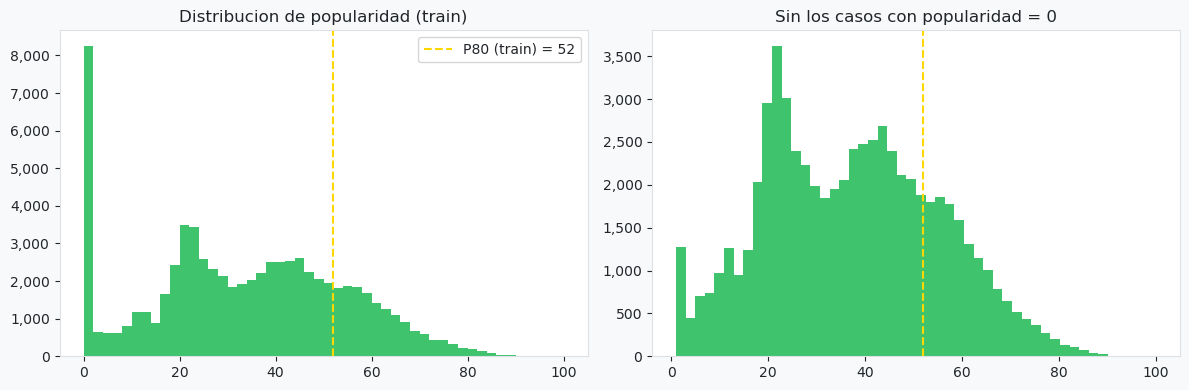

[graficos] Guardado: output\graficos\01_distribucion_popularidad.png
Canciones con popularity == 0 (train): 10.3%


In [3]:
gr.grafico_distribucion_popularidad(df, umbral)
print(f"Canciones con popularity == 0 (train): {(df.popularity == 0).mean()*100:.1f}%")

Hay un bloque grande de canciones con popularidad 0, que no es una cola natural de la distribución sino un salto en el origen. Más abajo vemos cómo se reparte por género.

Al definir `hit` como popularidad ≥ P80 de train, la proporción de positivos es ≈ 20% **por construcción** (hit rate train: 0,210; test: 0,205). No es un hallazgo sobre los datos sino una decisión de diseño, y supone un desbalance moderado 80/20. Por eso en la modelación se evalúa `class_weight="balanced"` frente a no usarlo, y se reportan métricas que no dependen solo de accuracy (PR-AUC, recall, precision, lift).

**Decisión sobre `popularity`:** no entra como variable predictora. El target se construye a partir de ella, así que usarla sería fuga directa; solo se usa para calcular el P80 en train y definir `hit`.

## 2. Variables de audio: distribución y asimetría

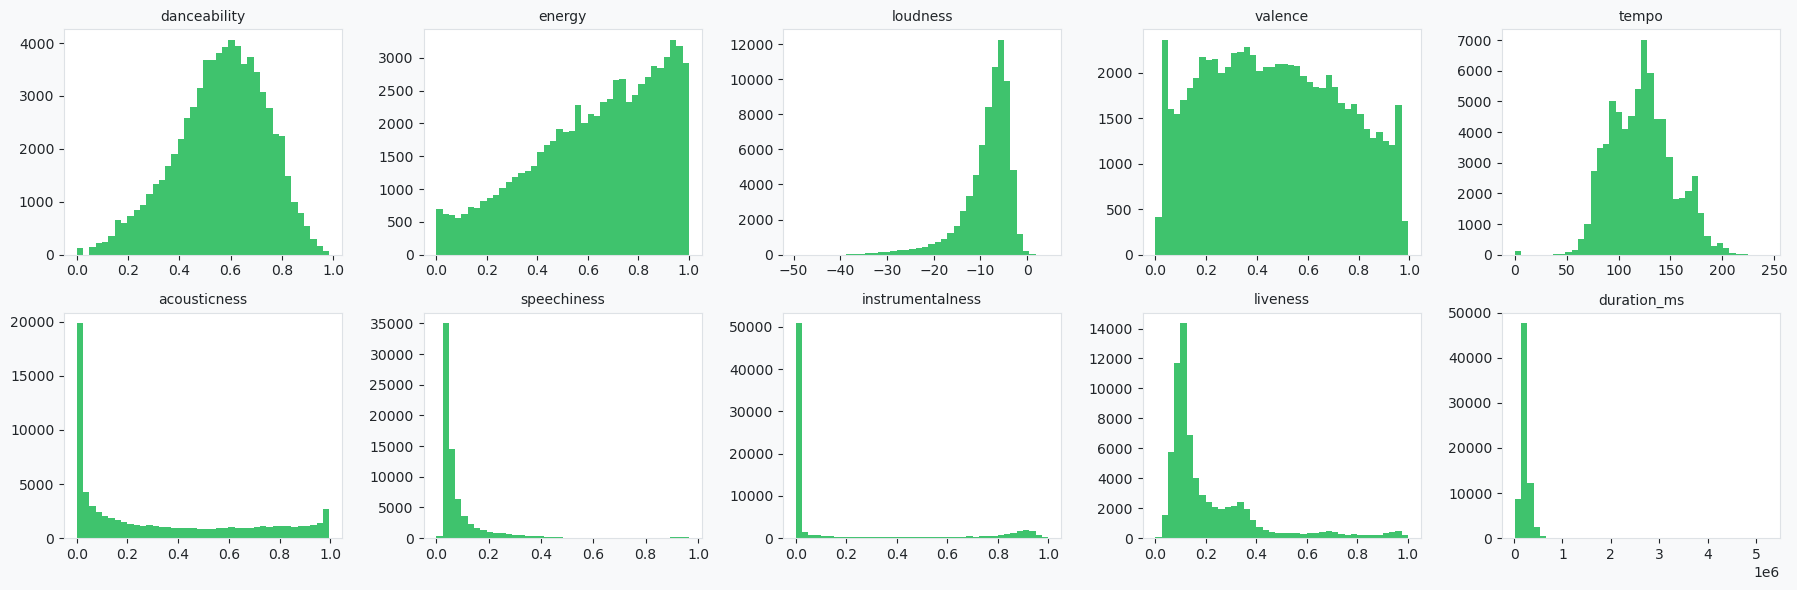

[graficos] Guardado: output\graficos\02_distribuciones_numericas.png


In [4]:
gr.grafico_distribuciones_numericas(df)

In [5]:
log_vars = ["speechiness", "instrumentalness", "liveness", "duration_ms"]
print("Asimetría (skew) de las variables transformadas con log1p (columnas *_log creadas en train):")
pd.DataFrame({"skew_original": df[log_vars].skew(),
              "skew_log1p": df[[f"{v}_log" for v in log_vars]].skew().values}).round(2)

Asimetría (skew) de las variables transformadas con log1p (columnas *_log creadas en train):


,skew_original,skew_log1p
speechiness,4.54,3.68
instrumentalness,1.56,1.48
liveness,2.07,1.72
duration_ms,10.39,-0.32


In [6]:
df[[c for c in num_cols if c not in log_vars]].skew().round(2).to_frame("skew")

,skew
danceability,-0.40
energy,-0.56
loudness,-1.96
valence,0.13
tempo,0.19
acousticness,0.66


`log1p` se aplica a cuatro variables: `speechiness` (4,54), `duration_ms` (10,39), `liveness` (2,07) e `instrumentalness` (1,56). La selección se hizo por inspección de la distribución y no por un umbral fijado de antemano: existe una brecha natural en los datos, ya que la siguiente variable más asimétrica (`acousticness`) cae a 0,66, una diferencia de casi 0,9 puntos. Por esa brecha, cualquier umbral entre 0,66 y 1,56 selecciona exactamente las mismas cuatro variables, de modo que la elección no depende del valor concreto de corte. El motivo práctico es que las colas largas dominan el escalado (la media y la desviación quedan arrastradas por pocos valores extremos) y las distancias que usa K-Means. `loudness` (−1,96) tiene asimetría negativa y valores negativos (dB), por lo que `log1p` no es aplicable y se deja sin transformar. HGB y Random Forest no cambian con transformaciones monótonas, así que la transformación solo afecta a la regresión logística y al K-Means; se aplica igual en las cuatro variables para que todos los modelos usen el mismo conjunto de features. La mejora es clara solo en `duration_ms` (10,39 → −0,32); en `speechiness` (4,54 → 3,68), `liveness` (2,07 → 1,72) e `instrumentalness` (1,56 → 1,48) es modesta, y las dos primeras siguen siendo asimétricas después de transformarlas.

**Decisión:** el modelo usa las cuatro versiones `_log` en lugar de las originales. Las otras seis variables de audio (`danceability`, `energy`, `loudness`, `valence`, `tempo`, `acousticness`) tienen asimetría baja o moderada (tabla anterior) y entran en su escala original.

## 2b. Transformaciones: escalado y codificación de género
**Escalado.** Se ajusta `StandardScaler` solo con train y se aplica a test; aquí se muestra como verificación (media ≈ 0 y desvío ≈ 1 en train). En la modelación el escalado va dentro del `Pipeline` (`src/train.py`), así que en validación cruzada se ajusta en cada fold.

**`key` y `time_signature`:** aunque vienen como enteros son nominales (el tono 11 no es "mayor" que el 0), así que en el `Pipeline` se codifican con `OneHotEncoder` en lugar de escalarse. `explicit` y `mode` ya son 0/1 y entran sin transformar.

In [7]:
from sklearn.preprocessing import StandardScaler
from src.pipeline import FEATURES_SCALE

sc = StandardScaler().fit(train[FEATURES_SCALE])   # se ajusta SOLO con train
z_train = pd.DataFrame(sc.transform(train[FEATURES_SCALE]), columns=FEATURES_SCALE)
z_test  = pd.DataFrame(sc.transform(test[FEATURES_SCALE]),  columns=FEATURES_SCALE)
pd.DataFrame({"media_train": z_train.mean(), "std_train": z_train.std(),
              "media_test": z_test.mean(),  "std_test": z_test.std()}).round(3)

,media_train,std_train,media_test,std_test
danceability,-0.0,1.0,-0.001,1.007
energy,-0.0,1.0,0.015,1.002
loudness,-0.0,1.0,0.008,1.014
valence,-0.0,1.0,0.002,1.001
tempo,-0.0,1.0,0.020,1.001
acousticness,0.0,1.0,-0.002,1.000
speechiness_log,0.0,1.0,0.008,0.992
instrumentalness_log,0.0,1.0,-0.008,0.995
liveness_log,-0.0,1.0,0.020,1.005
duration_ms_log,0.0,1.0,-0.012,1.005


**Género (multi-hot).** Cada canción conserva todos sus géneros en columnas `genre_*`, en lugar de perder los géneros extra con un `drop_duplicates` directo. La proporción de canciones con más de un género es la información que se habría perdido.

**Decisión:** el género entra como 114 columnas `genre_*` (multi-hot) y no como una sola etiqueta, para no perder los géneros de las canciones multigénero que muestra la celda siguiente.

In [8]:
genre_cols = [c for c in train.columns if c.startswith("genre_")]
assert (train[genre_cols].sum(axis=1) == train.n_generos).all()   # cada fila marca exactamente sus géneros
print(f"Columnas genre_* (multi-hot): {len(genre_cols)}")
print(f"Canciones con más de un género — train: {(train.n_generos > 1).mean()*100:.1f}% | test: {(test.n_generos > 1).mean()*100:.1f}%")

Columnas genre_* (multi-hot): 114
Canciones con más de un género — train: 18.1% | test: 18.6%


## 3. Sesgo de género
Como cada canción puede tener varios géneros, contamos la canción en **cada** uno de sus géneros. Las tasas se calculan solo con train.

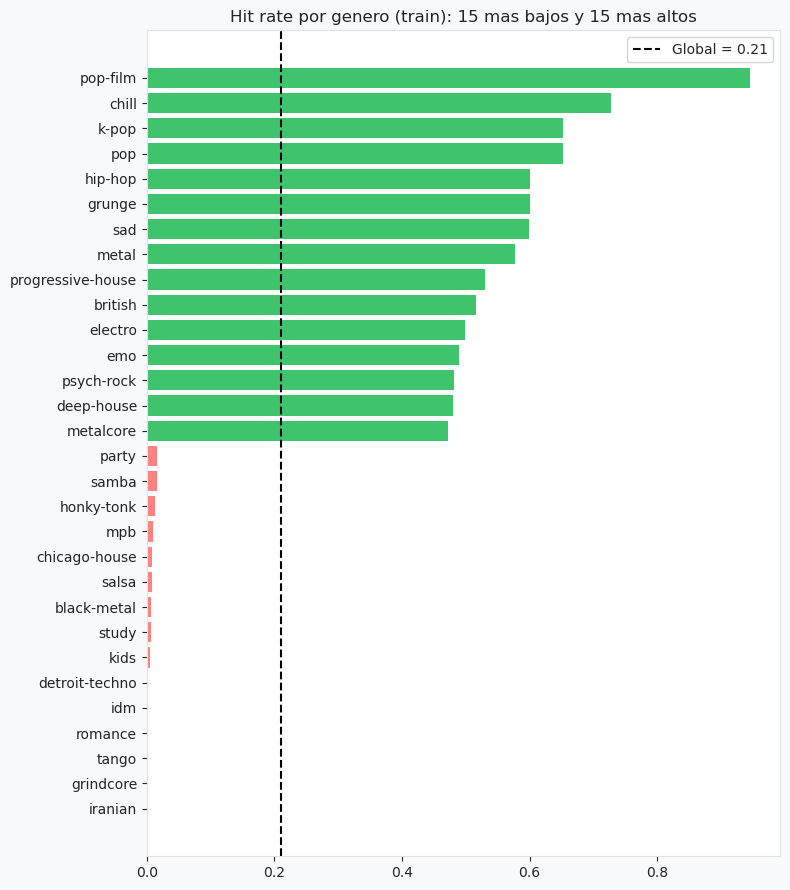

[graficos] Guardado: output\graficos\03_hit_rate_por_genero.png
Géneros: 114 | con 0 hits: 4 | con hit rate > 2x el global: 21
Rango de hit rate entre géneros: 0.00 – 0.95 (global 0.21)


In [9]:
tasa = gr.grafico_hit_rate_genero(df)

global_rate = df.hit.mean()
print(f"Géneros: {len(tasa)} | con 0 hits: {(tasa.hit_rate == 0).sum()} | "
      f"con hit rate > 2x el global: {(tasa.hit_rate > 2*global_rate).sum()}")
print(f"Rango de hit rate entre géneros: {tasa.hit_rate.min():.2f} – {tasa.hit_rate.max():.2f} (global {global_rate:.2f})")

In [10]:
# ¿Cuánto del "hit" se explica solo con el género?
# Las tasas por género salen SOLO de train; se mide el AUC en train (in-sample) y en test (fuera de muestra).
def auc_solo_genero(datos):
    gg = datos.assign(genero=datos.track_genre.str.split("|")).explode("genero")
    gg["tasa_genero"] = gg.genero.map(tasa.hit_rate).fillna(global_rate)   # género no visto -> tasa global
    score = gg.groupby("track_id").tasa_genero.mean()
    y = datos.set_index("track_id").hit.loc[score.index]
    return roc_auc_score(y, score)

print(f"AUC usando SOLO el hit rate del género -> train (in-sample): {auc_solo_genero(train):.3f} | test: {auc_solo_genero(test):.3f}")

AUC usando SOLO el hit rate del género -> train (in-sample): 0.837 | test: 0.831


El AUC solo con género es prácticamente igual en train (0.837) y en test (0.831): la cifra in-sample no resultó optimista, y el género por sí solo ya supera el KPI de 0.80. Las variables de audio, en cambio, tienen correlaciones individuales débiles (sección 5). Esto implica que el modelo puede apoyarse más en *dónde* está la canción que en *cómo suena*, y que cumplir el KPI de AUC no prueba por sí solo que el audio aporte. Por eso en la modelación se reporta el AUC con y sin género (ablación).

Además, como el dataset tiene la misma cantidad de filas por género, estas tasas reflejan el muestreo y no el mercado real.

**Decisión:** el género se mantiene como variable. Quitarlo dejaría fuera la señal más fuerte del dataset; en cambio, su peso y su efecto sobre el recall de cada género se miden en la modelación.

## 4. ¿Cuántos géneros tiene una canción y su relación con el hit?

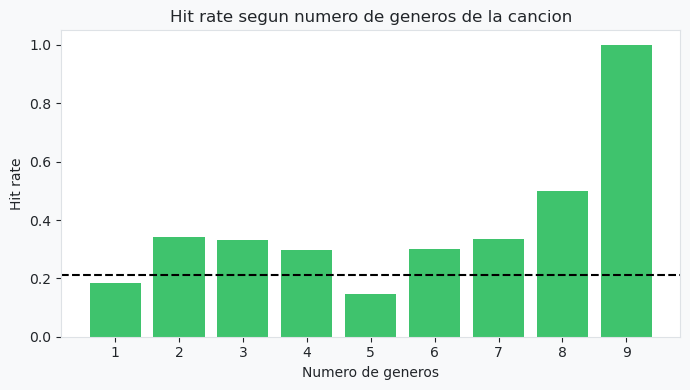

[graficos] Guardado: output\graficos\04_hit_rate_n_generos.png


,hit_rate,n
n_generos,,
1,0.184,58763
2,0.340,9138
3,0.333,2301
4,0.298,1055
5,0.147,348
6,0.300,80
7,0.333,18
8,0.500,2
9,1.000,1


In [11]:
gr.grafico_hit_rate_n_generos(df)

Las canciones de un solo género tienen un hit rate de 0,184 (n = 58.763) y las de dos o más de ≈ 0,33 (2 géneros: 0,340; 3: 0,333), aunque la relación no es monótona (5 géneros: 0,147, n = 348) y los grupos con 6 o más géneros son muy pequeños. `n_generos` no se incluye como variable, pero el multi-hot lo contiene de forma implícita (es la suma de las columnas `genre_*`); por eso en la modelación se revisa si el desempeño depende de ese conteo implícito, entrenando y evaluando solo con canciones de un género, donde el conteo es constante (sección 12 de `2_Modelacion`).

## 5. Relación de las variables con la popularidad

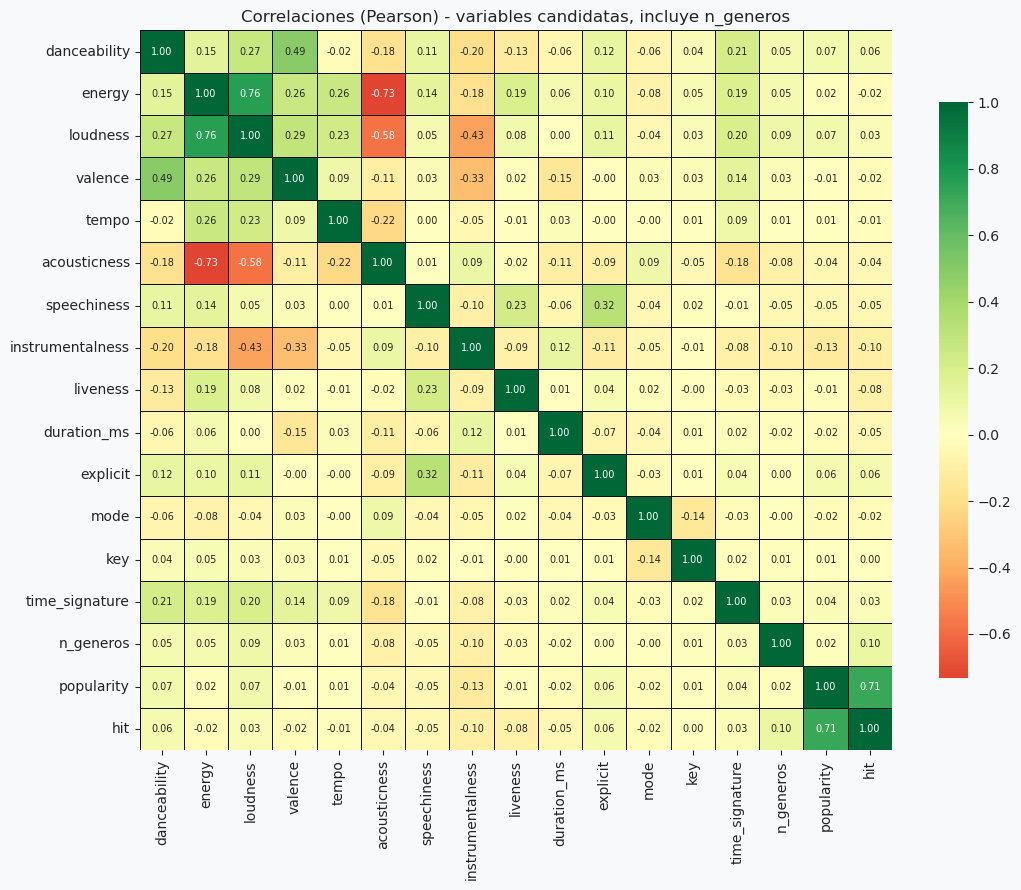

[graficos] Guardado: output\graficos\05_correlaciones.png


,instrumentalness,liveness,duration_ms,speechiness,acousticness,mode,valence,energy,tempo,key,time_signature,loudness,danceability,explicit,n_generos
corr con hit,-0.095,-0.085,-0.047,-0.045,-0.041,-0.024,-0.02,-0.018,-0.012,0.002,0.028,0.034,0.059,0.065,0.104


In [12]:
corr = gr.grafico_correlaciones(df, gr.CORR_COLS_CANDIDATAS, nombre="05_correlaciones.png",
                                titulo="Correlaciones (Pearson) - variables candidatas, incluye n_generos")
corr["hit"].drop(["hit", "popularity"]).sort_values().round(3).to_frame("corr con hit").T

`n_generos` tiene la correlación más alta con `hit` de esta matriz (r = 0,104), mayor que cualquier variable de audio o categórica. No se excluye por esa correlación en sí, sino por una sospecha sobre su origen: puede ser consecuencia del éxito (las canciones populares aparecen en más listas y, por tanto, acumulan más géneros al consolidar duplicados por `track_id`) y no una propiedad de la canción. Esta explicación es una hipótesis y no se prueba aquí. Además, `sum(genre_*)` permite recuperar la variable de forma implícita. Por eso en la modelación se revisa si el modelo depende de ese conteo implícito (sección 12 de `2_Modelacion`).

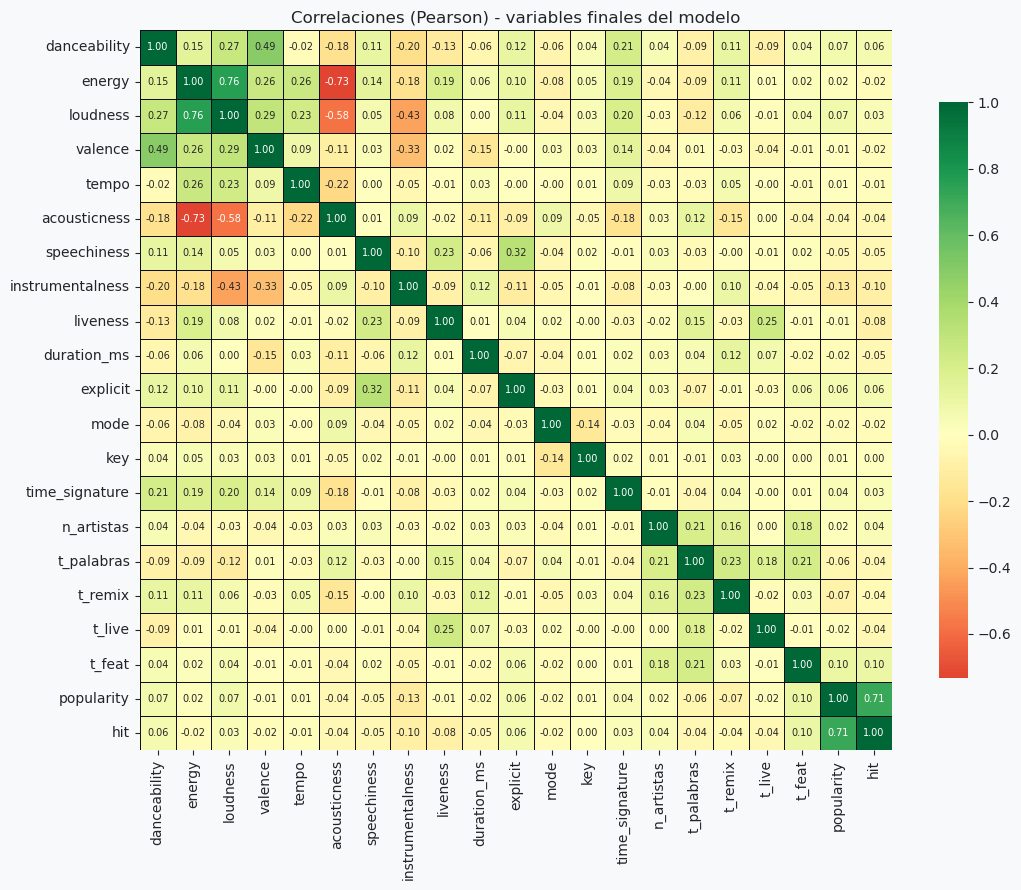

[graficos] Guardado: output\graficos\05b_correlaciones_finales.png


,instrumentalness,liveness,duration_ms,speechiness,t_palabras,t_live,acousticness,t_remix,mode,valence,energy,tempo,key,time_signature,loudness,n_artistas,danceability,explicit,t_feat
corr con hit,-0.095,-0.085,-0.047,-0.045,-0.044,-0.043,-0.041,-0.035,-0.024,-0.02,-0.018,-0.012,0.002,0.028,0.034,0.035,0.059,0.065,0.097


In [13]:
corr_fin = gr.grafico_correlaciones(df, gr.CORR_COLS_FINALES, nombre="05b_correlaciones_finales.png",
                                    titulo="Correlaciones (Pearson) - variables finales del modelo")
corr_fin["hit"].drop(["hit", "popularity"]).sort_values().round(3).to_frame("corr con hit").T

Esta segunda matriz usa exactamente las variables numericas/categoricas y de texto que entran al modelo (sin `n_generos`, que se descarto arriba, y sin las columnas `genre_*`, que son 114 y no caben en un mapa de calor). Sirve para revisar colinealidad entre las variables que sí se usan. La más alta está entre las de audio: `energy` con `loudness` (0,76), `energy` con `acousticness` (−0,73) y `loudness` con `acousticness` (−0,58). Entre las de texto es baja (la mayor, `t_palabras` con `t_remix`, 0,23). Se conservan las tres de audio: HGB y Random Forest toleran la colinealidad, y en la regresión logística solo afecta la lectura de cada coeficiente por separado, que en este proyecto no se interpreta. De las variables finales, la de mayor correlación con el hit es `t_feat` (0,097).

**Variables de texto:** `n_artistas`, `t_palabras`, `t_remix`, `t_live` y `t_feat` se derivan de `artists` y `track_name` sin usar el nombre del artista ni el target (la sección 7 explica por qué el nombre no se usa). Se mantienen: no son redundantes con el audio (la relación más alta es `t_live` con `liveness`, 0,25, esperable porque ambas marcan grabaciones en vivo) y `t_feat` es la variable final con mayor correlación con el hit.

In [14]:
cols_corr = [c for c in gr.CORR_COLS_FINALES if c in df.columns]
comp = pd.DataFrame({
    "pearson":  df[cols_corr].corrwith(df["hit"], method="pearson"),
    "spearman": df[cols_corr].corrwith(df["hit"], method="spearman"),
}).drop(["hit", "popularity"], errors="ignore").round(3)
comp.sort_values("spearman")

,pearson,spearman
instrumentalness,-0.095,-0.071
liveness,-0.085,-0.059
t_live,-0.043,-0.043
t_palabras,-0.044,-0.042
speechiness,-0.045,-0.036
t_remix,-0.035,-0.035
duration_ms,-0.047,-0.033
energy,-0.018,-0.029
mode,-0.024,-0.024
valence,-0.020,-0.018


Se reporta Pearson por ser la medida estándar, pero varias variables son muy asimétricas (por ejemplo `duration_ms`, con asimetría 10,39) y el target es binario; en ese caso Pearson equivale a una correlación punto-biserial y es sensible a valores extremos. Por eso se calcula también Spearman, que es invariante a transformaciones monótonas (da lo mismo con la variable original o con su versión `_log`). Ordenadas por |Spearman| de mayor a menor:

| Variable | Pearson | Spearman |
|---|---|---|
| `t_feat` | 0,097 | 0,097 |
| `instrumentalness` | −0,095 | −0,071 |
| `explicit` | 0,065 | 0,065 |
| `liveness` | −0,085 | −0,059 |
| `loudness` | 0,034 | 0,056 |
| `danceability` | 0,059 | 0,054 |
| `n_artistas` | 0,035 | 0,052 |
| `t_live` | −0,043 | −0,043 |
| `t_palabras` | −0,044 | −0,042 |
| `speechiness` | −0,045 | −0,036 |
| `t_remix` | −0,035 | −0,035 |
| `duration_ms` | −0,047 | −0,033 |
| `energy` | −0,018 | −0,029 |
| `time_signature` | 0,028 | 0,026 |
| `mode` | −0,024 | −0,024 |
| `valence` | −0,020 | −0,018 |
| `tempo` | −0,012 | −0,016 |
| `acousticness` | −0,041 | −0,016 |
| `key` | 0,002 | 0,002 |

Con ambas medidas todas las correlaciones son débiles (|ρ| ≤ 0,097) y los signos no cambian. Las variables binarias (`explicit`, `mode`, `t_feat`, `t_live`, `t_remix`) dan el mismo valor con las dos medidas. Entre las demás hay cambios de orden: con Spearman bajan `instrumentalness` (−0,095 → −0,071), `liveness` (−0,085 → −0,059) y `acousticness` (−0,041 → −0,016), y suben `loudness` (0,034 → 0,056) y `n_artistas` (0,035 → 0,052). Parte de la correlación de Pearson en las variables asimétricas viene de los valores extremos. La conclusión no depende de la medida: ninguna variable separa hits por sí sola.

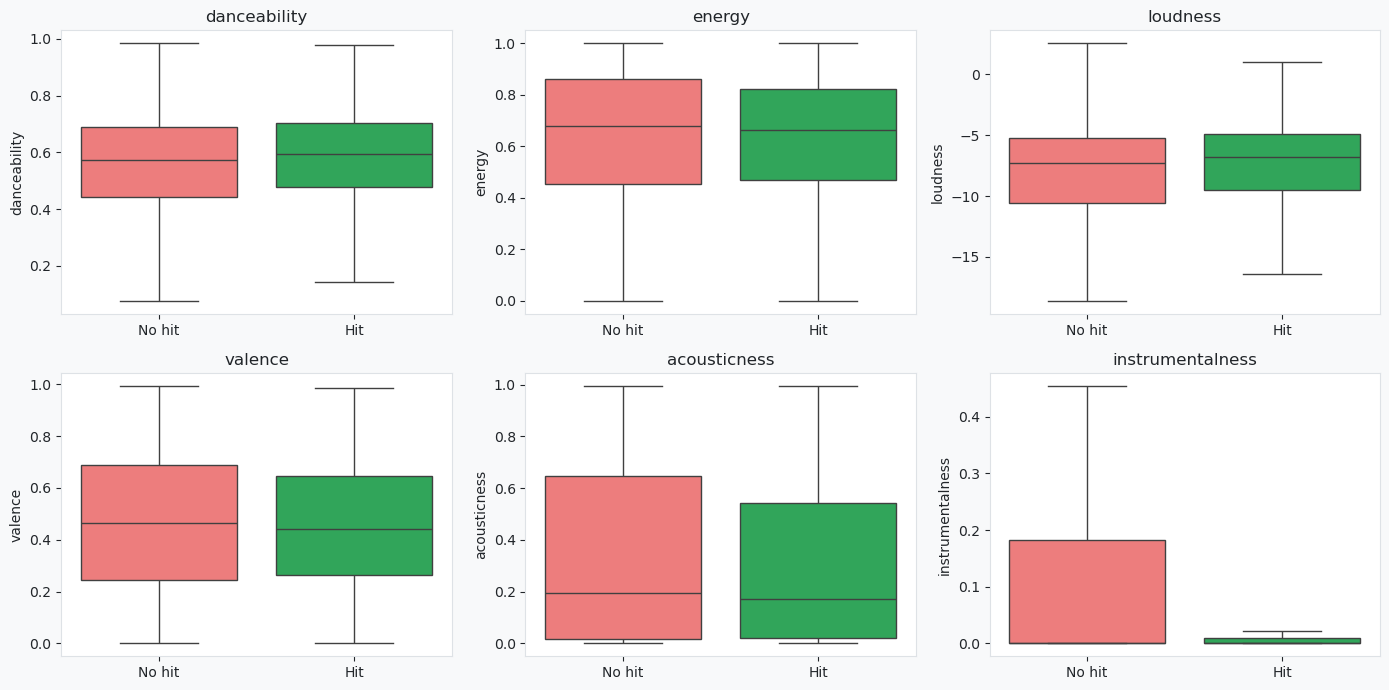

[graficos] Guardado: output\graficos\06_features_por_clase.png


In [15]:
gr.grafico_features_por_clase(df)

In [16]:
df.groupby("explicit").hit.agg(["mean", "size"]).rename(index={0: "No explícita", 1: "Explícita", False: "No explícita", True: "Explícita"}).round(3)

,mean,size
explicit,,
No explícita,0.202,65557
Explícita,0.296,6149


Las correlaciones individuales con el hit son débiles: la mayor es |r| = 0,095 (instrumentalness), seguida de liveness (−0,085) y explicit (0,065); el resto queda bajo 0,06 en valor absoluto. Ninguna variable de audio separa por sí sola. explicit merece un matiz: su correlación es pequeña, pero el hit rate es 0,296 en canciones explícitas frente a 0,202 en las no explícitas (n = 6.149 y 65.557), unos 9 puntos de diferencia que aquí no se separan del efecto del género. Que las correlaciones sean bajas no implica que el audio no aporte: es una hipótesis (la señal podría estar en combinaciones no lineales) que se evalúa en la modelación.

Las correlaciones se calculan sobre las variables originales; el modelo usa las versiones `_log` de `speechiness`, `instrumentalness`, `liveness` y `duration_ms`.

**Decisión:** ninguna variable de audio se descarta por tener correlación individual baja, porque la señal puede estar en combinaciones que la correlación no mide (se evalúa en la modelación). `explicit` se mantiene por la diferencia de hit rate de la celda anterior.

## 6. Popularidad = 0

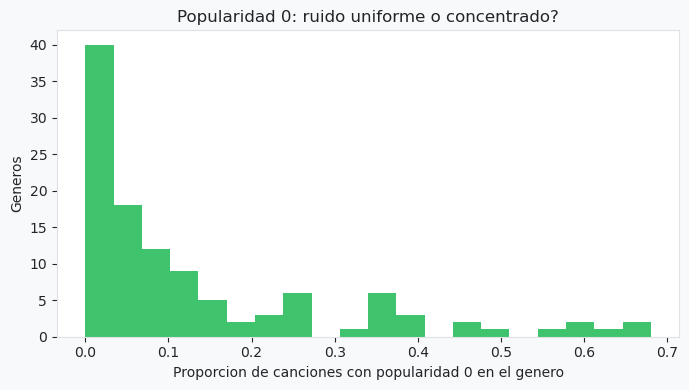

[graficos] Guardado: output\graficos\07_popularidad_cero.png
Géneros con más del 50% de canciones en popularidad 0: 7
Los 10 géneros con mayor proporción de popularidad 0:
genero
jazz           0.68
iranian        0.67
romance        0.62
soul           0.59
country        0.58
latin          0.56
rock           0.51
alternative    0.47
dance          0.47
house          0.41


In [17]:
cero = gr.grafico_popularidad_cero(df)
print(f"Géneros con más del 50% de canciones en popularidad 0: {(cero > 0.5).sum()}")
print("Los 10 géneros con mayor proporción de popularidad 0:")
print(cero.head(10).round(2).to_string())

In [18]:
df.groupby(df.popularity == 0)[["duration_ms", "explicit", "instrumentalness", "danceability"]].mean().rename(index={True: "popularidad = 0", False: "popularidad > 0"}).round(3)

,duration_ms,explicit,instrumentalness,danceability
popularity,,,,
popularidad > 0,230953.584,0.086,0.179,0.563
popularidad = 0,214958.516,0.080,0.129,0.554


La popularidad 0 **no** es ruido uniforme: se concentra en ciertos géneros (jazz, iranian, romance, soul, country, latin y rock superan el 50%). Eliminarla borraría buena parte de esos géneros y crearía un sesgo propio. Por eso no se elimina: sigue contando como "no hit" y se documenta como limitación (puede reflejar canciones sin datos de popularidad más que canciones realmente impopulares).

En la comparación de promedios de la celda anterior, `danceability` (0.554 frente a 0.563) y la proporción de canciones explícitas (0.080 frente a 0.086) casi no cambian; `instrumentalness` (0.129 frente a 0.179) y la duración (unos 16.000 ms menos) sí difieren, aunque de forma moderada. La concentración por género es la señal más clara de la popularidad 0.

Para ver si la popularidad 0 también se concentra en artistas (y no solo en géneros), se mide cuántos artistas con 5 o más canciones tienen **todas** sus canciones en popularidad 0.

In [19]:
ex0 = ex.assign(cero=(df.loc[ex.index, "popularity"] == 0).values)
por_art = ex0.groupby("artista")["cero"].agg(["mean", "size"])
art5 = por_art[por_art["size"] >= 5]
print(f"Artistas con 5 o más canciones: {len(art5):,}")
print(f"  con TODAS sus canciones en popularidad 0: {(art5['mean'] == 1).sum():,} ({(art5['mean'] == 1).mean()*100:.1f}%)")
print(f"  con la mitad o más en popularidad 0: {(art5['mean'] >= 0.5).sum():,} ({(art5['mean'] >= 0.5).mean()*100:.1f}%)")
print(f"Proporción global de canciones con popularidad 0 (train): {(df.popularity == 0).mean()*100:.1f}%")

Artistas con 5 o más canciones: 4,957
  con TODAS sus canciones en popularidad 0: 121 (2.4%)
  con la mitad o más en popularidad 0: 533 (10.8%)
Proporción global de canciones con popularidad 0 (train): 10.3%


De los 4.957 artistas con 5 o más canciones, 121 (2,4%) tienen **todas** sus canciones en popularidad 0 y 533 (10,8%) tienen la mitad o más, con una proporción global de 10,3%. Si los ceros estuvieran repartidos al azar, tener la mitad o más en 0 sería del orden de 0,2% a 1,7% según el número de canciones del artista (0,93% con 5 y 1,72% con 6), y tenerlas todas en 0 sería prácticamente imposible (≈ 0,001% con 5 canciones). Por tanto la popularidad 0 se concentra también en artistas, no solo en géneros. No se puede separar del todo del efecto del género (los artistas de géneros con muchos ceros comparten ambos), y refuerza la lectura de que puede reflejar falta de dato más que impopularidad real.

Con el umbral P80 > 0, una canción con popularidad 0 queda como "no hit" tanto si es realmente impopular como si carece de dato. Imputar esos valores solo cambiaría la etiqueta si se les asignara un valor por encima del umbral, lo que no tiene respaldo en los datos. Mantenerlos como "no hit" es la opción más conservadora. Lo observado (concentración por género y por artista, muy por encima del azar) es compatible con dos explicaciones que este EDA no puede distinguir: falta de dato o géneros y artistas realmente poco populares. Para medir cuánto afecta, en la modelación se compara el desempeño con y sin las filas de popularidad 0 (análisis de sensibilidad).

## 7. Versiones de una misma canción y artistas

In [20]:
sz = df.groupby("grupo").size()
rango = df.groupby("grupo").popularity.agg(lambda s: s.max() - s.min())
cruza = df.groupby("grupo").hit.nunique()
print(f"Combinaciones artista+título con más de un track_id (en train): {(sz > 1).sum():,}")
print(f"Entre ellas (en train), popularidad que difiere en más de 10 puntos: {((sz > 1) & (rango > 10)).sum():,}")
print(f"Grupos con versiones en ambas clases, en train (hit y no hit): {(cruza > 1).sum():,}")

Combinaciones artista+título con más de un track_id (en train): 3,783
Entre ellas (en train), popularidad que difiere en más de 10 puntos: 1,422
Grupos con versiones en ambas clases, en train (hit y no hit): 1,061


Las colaboraciones vienen como `A;B`, así que se miden dos niveles: la **cadena completa** y cada **artista individual**. Como el hit rate global es ≈ 0.21, un artista con pocas canciones tendría todas no-hit con frecuencia incluso por azar; por eso la proporción observada se compara con una **línea base** en la que las etiquetas `hit` se barajan entre canciones.

In [21]:
def todo_o_nada(grupos, hit, min_n=5):
    """Artistas con min_n o más canciones y proporción de ellos con todas sus canciones hit o todas no hit."""
    a = pd.DataFrame({"g": np.asarray(grupos), "hit": np.asarray(hit)}).groupby("g")["hit"].agg(["mean", "size"])
    a = a[a["size"] >= min_n]
    return len(a), ((a["mean"] == 0) | (a["mean"] == 1)).mean()

def base_azar(grupos, idx, reps=100, seed=42):
    """Misma proporción si las etiquetas hit se barajan entre canciones (sin relación con el artista)."""
    rng = np.random.RandomState(seed)
    props = []
    for _ in range(reps):
        h = pd.Series(rng.permutation(df["hit"].values), index=df.index).loc[idx].values
        props.append(todo_o_nada(grupos, h)[1])
    return np.mean(props), np.percentile(props, [2.5, 97.5])

for nombre, grupos, hit, idx in [
        ("cadena completa de artistas", df["artists"], df["hit"], df.index),
        ("artista individual (separado por ';')", ex["artista"], ex["hit"], ex.index)]:
    n_unicos = pd.Series(np.asarray(grupos)).nunique()
    n5, prop = todo_o_nada(grupos, hit)
    azar, (lo, hi) = base_azar(grupos, idx)
    print(f"[{nombre}] únicos: {n_unicos:,} | con 5 o más canciones: {n5:,} | "
          f"todas hit o todas no hit: {prop*100:.1f}% | por azar (etiquetas barajadas): {azar*100:.1f}% "
          f"(rango 2.5%-97.5% de las simulaciones: {lo*100:.1f}%-{hi*100:.1f}%)")

art_train = set(ex["artista"])
sep_test = test.artists.str.split(";")
print(f"\nCanciones de test cuya cadena de artistas aparece en train: {test.artists.isin(set(train.artists)).mean()*100:.1f}%")
print(f"Canciones de test con al menos un artista individual que aparece en train: "
      f"{sep_test.apply(lambda L: any(a.strip() in art_train for a in L)).mean()*100:.1f}%")

[cadena completa de artistas] únicos: 27,039 | con 5 o más canciones: 3,109 | todas hit o todas no hit: 63.4% | por azar (etiquetas barajadas): 15.1% (rango 2.5%-97.5% de las simulaciones: 14.2%-16.4%)
[artista individual (separado por ';')] únicos: 26,528 | con 5 o más canciones: 4,957 | todas hit o todas no hit: 55.2% | por azar (etiquetas barajadas): 14.7% (rango 2.5%-97.5% de las simulaciones: 13.7%-15.6%)

Canciones de test cuya cadena de artistas aparece en train: 72.1%
Canciones de test con al menos un artista individual que aparece en train: 91.7%


**Regularidad por artista.** Está muy por encima del azar: con la cadena completa (3.109 artistas con 5 o más canciones) el 63,4% tiene todas sus canciones hit o todas no hit, frente a 15,1% al barajar las etiquetas (rango 14,2%–16,4%); por artista individual (4.957 artistas) es 55,2% frente a 14,7% (rango 13,7%–15,6%).

**Solapamiento entre train y test.** El 72,1% de las canciones de test tiene la misma cadena de artistas en train, y el 91,7% tiene al menos un artista individual en común. Como el split se agrupa por canción y no por artista, casi todo el test contiene artistas ya vistos en train, y los artistas tienden a repetir su resultado: las métricas pueden ser algo optimistas respecto de artistas nuevos. Es una limitación a declarar en el informe.

**Decisión:** `artists`, `album_name` y `track_name` no entran como texto, y tampoco se usa una tasa histórica de hits por artista. Con el 72,1% del test compartiendo artista con train y artistas que repiten su resultado en bloque, el modelo memorizaría artistas en lugar de evaluar la canción. Esas columnas solo se usan para construir `song_key` (la clave del split) y las 5 variables de texto de la sección 5.

## 8. Cierre: guardar el split processed
Con el análisis terminado, se aplican las transformaciones definidas arriba (`log1p`, target `hit` con el P80 de train, multi-hot de géneros) y se guarda `data/processed/train|test`. **No se vuelve a dividir:** son las mismas filas y el mismo orden que raw. El `StandardScaler` no se aplica aquí: va dentro del `Pipeline` de `src/train.py` y se ajusta en cada fold.

**Matriz final: 133 variables** (10 de audio, `key`, `time_signature`, `explicit`, `mode`, 5 de texto y 114 `genre_*`). `Unnamed: 0` se descartó en la exploración inicial (es el índice del CSV). `track_id` no entra: es un identificador y solo permitiría memorizar canciones; se guarda en `id_*.csv` para la trazabilidad raw ↔ processed.

In [22]:
res = generar_processed()   # etapa 2: lee raw_train/raw_test, transforma y guarda data/processed
print(f"Processed train: {len(res['train_proc']):,} | test: {len(res['test_proc']):,} | "
      f"umbral P80 (train): {res['threshold']} | columnas genre_*: {len(res['genre_cols'])}")

[pipeline] Aplicando transformaciones a Train...
[pipeline] Umbral de popularidad (P80) calculado en TRAIN: 52.0
[pipeline] Aplicando transformaciones a Test...
[pipeline] Guardando datos procesados...
[pipeline] Processed Train: 71706, Processed Test: 18034
[pipeline] Trazabilidad OK: processed = mismas filas que raw (mismo orden).
Processed train: 71,706 | test: 18,034 | umbral P80 (train): 52.0 | columnas genre_*: 114


## Conclusiones del EDA y sesgos identificados

1. **Objetivo:** el P80 deja ~20% de hits por construcción, lo que implica un desbalance moderado. Se usa `class_weight="balanced"` y en la modelación se comprueba qué aporta frente a no usarlo (sección 2b); se reportan métricas que no dependen solo de accuracy (PR-AUC, recall, precision, lift).
2. **Asimetría:** `speechiness`, `instrumentalness`, `liveness` y `duration_ms` se transforman con `log1p`; el resto se escala.
3. **Género:** es la variable con más peso sobre el hit (el AUC solo con género se mide en train y en test en la sección 3, frente a correlaciones de audio muy débiles). Se conserva (multi-hot, sin perder información), pero se mide su aporte con una ablación y se revisa el recall por género.
4. **`n_generos`:** no se incluye como variable por sospecha de ser un efecto y no una causa de la popularidad (hipótesis no probada en el EDA); el multi-hot la contiene de forma implícita, y en la modelación se revisa si el modelo depende de ese conteo (sección 12).
5. **Popularidad 0:** concentrada en ciertos géneros; no se elimina y se documenta como limitación.
6. **Versiones y artistas:** el split se agrupa por artista + título para evitar fuga. Además, hay canciones que figuran como hit en una versión y como no hit en otra, lo que introduce ambigüedad en la etiqueta. Los artistas con varias canciones tienden a ser hit o no hit en bloque, de modo que un split por canción (no por artista) puede resultar optimista; es una limitación a declarar en el informe (la sección 7 mide cuánto del test comparte artista con train, por cadena completa y por artista individual, y compara la regularidad por artista contra una línea base de etiquetas barajadas).
7. **Muestreo por género:** el dataset tiene la misma cantidad de filas por género, así que los resultados no se pueden extrapolar sin cuidado a la distribución real de Spotify.